In [46]:
import matplotlib.pyplot as plt
import matplotlib
import numpy
from scipy import signal
import pandas as pd
from rascil.processing_components import create_visibility_from_ms
from ska_sdp_func_python.visibility import subtract_visibility
from ska_sdp_func_python.imaging import invert_ng, predict_ng, create_image_from_visibility
import os

from radioimaging.visibility import residual
from radioimaging.images import images
from radioimaging.util import util
from radioimaging.evaluation import evaluation
from radioimaging.deconvolution import deconvolve

import split

import logging

plt.set_loglevel("critical")
cmap='turbo'
matplotlib.rcParams['figure.figsize'] = [10, 5]

wavelet_type_dict = {"daubechies" : 0, "iuwt" : 1}

wavelet_type = "daubechies"
wavelet_type_idx = wavelet_type_dict[wavelet_type]

runtests = False
niter = 100

In [22]:
def deconvms(dirty, psf, lowres, niter, wavelet_type_idx, curr_maj_iter, initial_lambda, lambda_mul, cut_center=20, cut_halfwidth=5, variance_window=5, recon_variance_factor=1, lowin=None, vis_variance=None, recon_variance=None):
    curr_lambda = initial_lambda * (lambda_mul ** curr_maj_iter)
    curr_lambda *= numpy.linalg.norm(dirty)

    tmp_psf_name = "tmp_psf.fits"
    tmp_res_name = "tmp_residual.fits"
    tmp_lowin_name = "tmp_lowin.fits"
    tmp_output_name = "tmp_output.fits"

    helpers.write_nparr_to_fits(psf, tmp_psf_name)
    helpers.write_nparr_to_fits(dirty, tmp_res_name)

    #low resolution step if no constraint
    if lowin is None:
        os.system("julia ../julia_rascil_scripts/make_lowres.jl " + str(curr_lambda) + " " + tmp_psf_name + " " + tmp_res_name + " " + str(wavelet_type_idx) + " " + str(niter) + " " + tmp_output_name)
    else:
        #auto calculate sigma and eta if none provided
        if vis_variance is None:
            vis_variance = numpy.mean(deconvolve.compute_windowed_var(dirty, variance_window))
            recon_variance = vis_variance / recon_variance_factor

        util.tofits(lowres, tmp_lowin_name)

        os.system("julia ../julia_rascil_scripts/make_multistep.jl " + str(curr_lambda) + " " + tmp_psf_name + " " + tmp_res_name + " " + tmp_lowin_name + " " + str(wavelet_type_idx) + " " + str(niter) + " " + \
                str(recon_variance) + " " + str(vis_variance) + " " + str(cut_center) + " " + str(cut_halfwidth) + " " + tmp_output_name)

    deconvolved = helpers.fromfits(tmp_output_name)

    return deconvolved

## Original Databases

In [2]:
%%capture

logging.getLogger().setLevel(logging.CRITICAL)

[va] = create_visibility_from_ms('../data/SGRA.ms')
[vb] = create_visibility_from_ms('../data/SGRB.ms')
[vc] = create_visibility_from_ms('../data/SGRC.ms')

cell_size = 0.00001849451

dirty_a, psf_a = residual.dirty_psf_from_visibilities(va,cell_size,npix=512,weighting="uniform")
dirty_b, psf_b = residual.dirty_psf_from_visibilities(vb,cell_size,npix=512,weighting="uniform")
dirty_c, psf_c = residual.dirty_psf_from_visibilities(vc,cell_size,npix=512,weighting="uniform")

logging.getLogger().setLevel(logging.NOTSET)

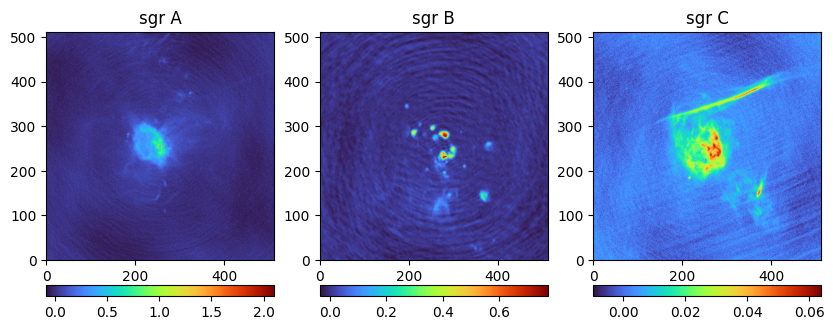

In [3]:
util.plotNImages([dirty_a.pixels.data[0,0,:,:], dirty_b.pixels.data[0,0,:,:], \
                     dirty_c.pixels.data[0,0,:,:]], ["sgr A", "sgr B", "sgr C"], cmap)

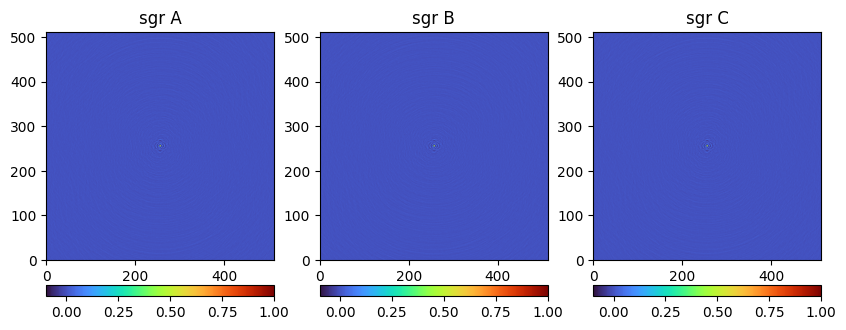

In [4]:
util.plotNImages([psf_a.pixels.data[0,0,:,:], psf_b.pixels.data[0,0,:,:], psf_c.pixels.data[0,0,:,:]], ["sgr A", "sgr B", "sgr C"], cmap)

## Cuts to visibilities

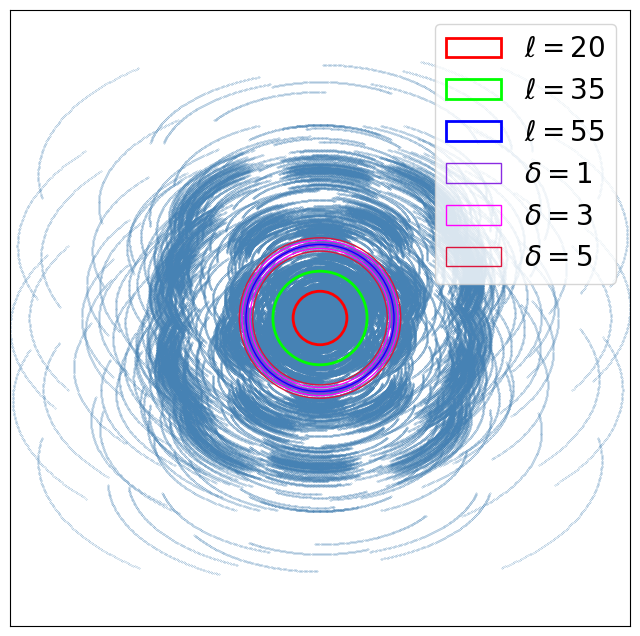

In [5]:
matplotlib.rcParams['figure.figsize'] = [8, 8]

nrows,nbaselines, _ = va.uvw.shape
uv = numpy.array(va.visibility_acc.uvw_lambda[...,0:2])
uv = uv.reshape(nrows*nbaselines,2)

centers = [20, 35, 55]
center_cols = ["red", "lime", "blue"]

halfwidths = [1, 3, 5]
halfwidth_cols = ["blueviolet", "fuchsia", "crimson"]


#plt.title('Visibility cut centers')
max_xy = numpy.max([numpy.max(numpy.fabs(uv[:,0])), numpy.max(numpy.fabs(uv[:,1]))])
plt.scatter(uv[:,0],uv[:,1],c='steelblue',marker='.', s=0.1)
plt.scatter(-uv[:,0],-uv[:,1],c='steelblue',marker='.', s=0.1)
plt.xticks([])
plt.yticks([])
plt.xlim([-max_xy, max_xy])
plt.ylim([-max_xy, max_xy])
ax = plt.gca()

for i, center in enumerate(centers):
    center_lambda = center / (512 * cell_size)
    circ = plt.Circle((0, 0), center_lambda, edgecolor=center_cols[i], facecolor="none", lw=2, label="$\ell=" + str(center) + "$")
    ax.add_patch(circ)
    
center_lambda = 55 / (512 * cell_size)

for i, hw in enumerate(halfwidths):
    outer = (55 + hw) / (512 * cell_size)
    inner = (55 - hw) / (512 * cell_size)
    circ_outer = plt.Circle((0, 0), outer, edgecolor=halfwidth_cols[i], facecolor="none", lw=1, label="$\delta=" + str(hw) + "$")
    circ_inner = plt.Circle((0, 0), inner, edgecolor=halfwidth_cols[i], facecolor="none", lw=1)
    ax.add_patch(circ_outer)
    ax.add_patch(circ_inner)

plt.legend(loc="upper right", fontsize=20)
    
plt.savefig("../figures/partition_centers.png", bbox_inches='tight')

## Different Halfwidths

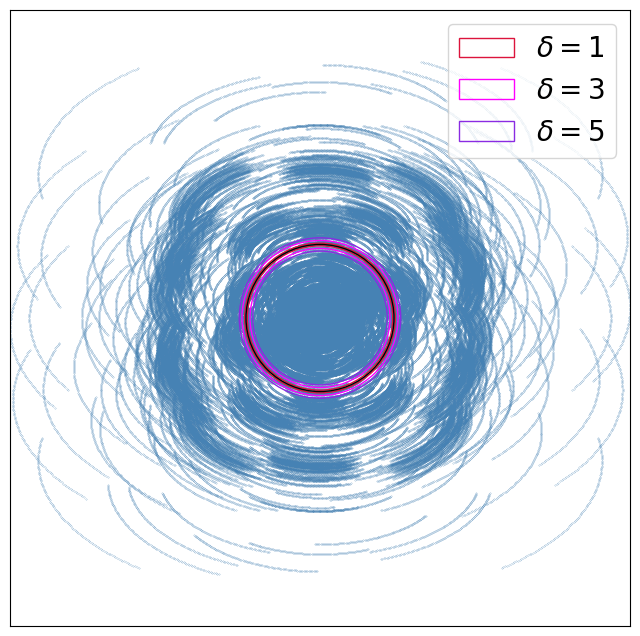

In [6]:
halfwidths = [1, 3, 5]
halfwidth_cols = ["crimson", "fuchsia", "blueviolet"]

#plt.title('Visibility cut halfwidths')
plt.scatter(uv[:,0],uv[:,1],c='steelblue',marker='.', s=0.1)
plt.scatter(-uv[:,0],-uv[:,1],c='steelblue',marker='.', s=0.1)
plt.xticks([])
plt.yticks([])
plt.xlim([-max_xy, max_xy])
plt.ylim([-max_xy, max_xy])
ax = plt.gca()

center_lambda = 55 / (512 * cell_size)

for i, hw in enumerate(halfwidths):
    outer = (55 + hw) / (512 * cell_size)
    inner = (55 - hw) / (512 * cell_size)
    circ_outer = plt.Circle((0, 0), outer, edgecolor=halfwidth_cols[i], facecolor="none", lw=1, label="$\delta=" + str(hw) + "$")
    circ_inner = plt.Circle((0, 0), inner, edgecolor=halfwidth_cols[i], facecolor="none", lw=1)
    ax.add_patch(circ_outer)
    ax.add_patch(circ_inner)
    
plt.legend(loc="upper right", fontsize=20)

circ = plt.Circle((0, 0), center_lambda, edgecolor="black", facecolor="none", lw=1)
ax.add_patch(circ)
    
plt.savefig("../figures/partition_halfwidths.png", bbox_inches='tight')

## Long and Small baseline databases

### Difference between halfwidths

In [7]:
%%capture

logging.getLogger().setLevel(logging.CRITICAL)

matplotlib.rcParams['figure.figsize'] = [10, 5]

[va1l] = create_visibility_from_ms('../data4/SGRA_long_baselines_19.ms')
[va1s] = create_visibility_from_ms('../data4/SGRA_small_baselines_21.ms')
[va3l] = create_visibility_from_ms('../data4/SGRA_long_baselines_17.ms')
[va3s] = create_visibility_from_ms('../data4/SGRA_small_baselines_23.ms')
[va5l] = create_visibility_from_ms('../data4/SGRA_long_baselines_15.ms')
[va5s] = create_visibility_from_ms('../data4/SGRA_small_baselines_25.ms')

dirty_a1l, psf_a1l = residual.dirty_psf_from_visibilities(va1l,cell_size,npix=512,weighting="uniform")
dirty_a1s, psf_a1s = residual.dirty_psf_from_visibilities(va1s,cell_size,npix=512,weighting="uniform")
dirty_a3l, psf_a3l = residual.dirty_psf_from_visibilities(va3l,cell_size,npix=512,weighting="uniform")
dirty_a3s, psf_a3s = residual.dirty_psf_from_visibilities(va3s,cell_size,npix=512,weighting="uniform")
dirty_a5l, psf_a5l = residual.dirty_psf_from_visibilities(va5l,cell_size,npix=512,weighting="uniform")
dirty_a5s, psf_a5s = residual.dirty_psf_from_visibilities(va5s,cell_size,npix=512,weighting="uniform")

logging.getLogger().setLevel(logging.NOTSET)

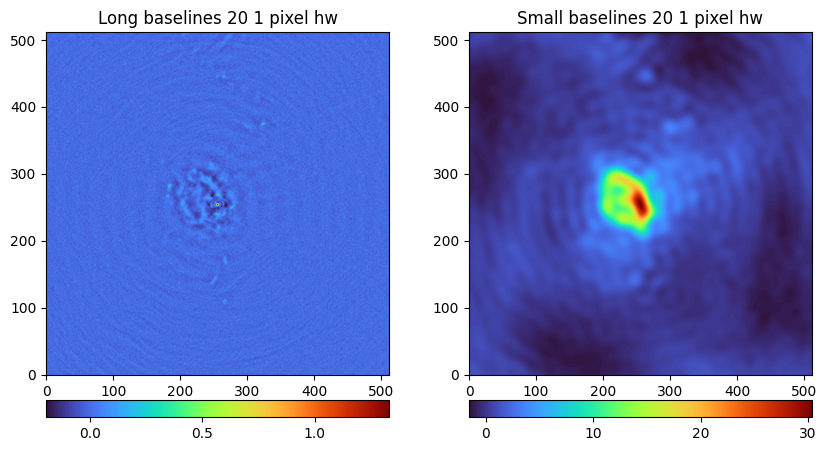

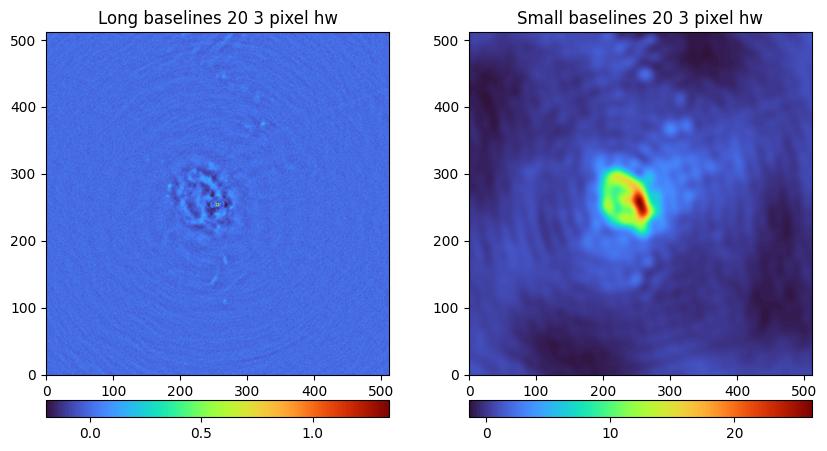

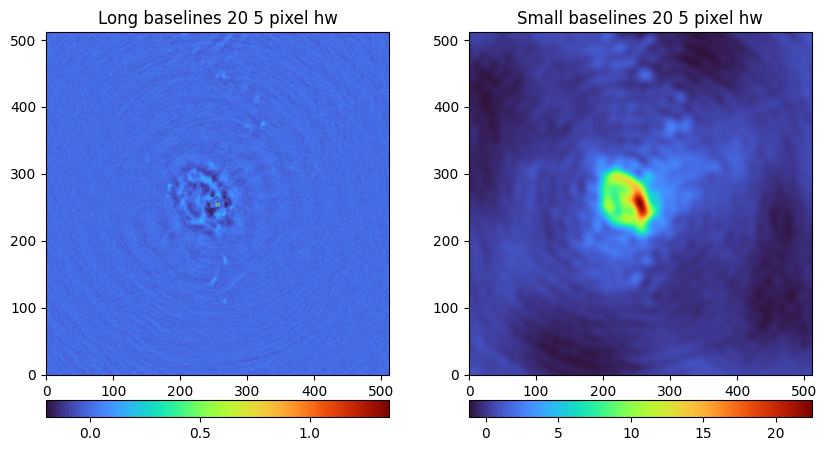

In [8]:
util.plotNImages([dirty_a1l.pixels.data[0,0,:,:], dirty_a1s.pixels.data[0,0,:,:]], \
                    ["Long baselines 20 1 pixel hw", "Small baselines 20 1 pixel hw"], cmap)
util.plotNImages([dirty_a3l.pixels.data[0,0,:,:], dirty_a3s.pixels.data[0,0,:,:]], \
                    ["Long baselines 20 3 pixel hw", "Small baselines 20 3 pixel hw"], cmap)
util.plotNImages([dirty_a5l.pixels.data[0,0,:,:], dirty_a5s.pixels.data[0,0,:,:]], \
                    ["Long baselines 20 5 pixel hw", "Small baselines 20 5 pixel hw"], cmap)

### Difference between cuts

#### sgr A

In [9]:
%%capture

logging.getLogger().setLevel(logging.CRITICAL)

[val1] = create_visibility_from_ms('../data4/SGRA_long_baselines_15.ms')
[vas1] = create_visibility_from_ms('../data4/SGRA_small_baselines_25.ms')
[val2] = create_visibility_from_ms('../data4/SGRA_long_baselines_30.ms')
[vas2] = create_visibility_from_ms('../data4/SGRA_small_baselines_40.ms')
[val3] = create_visibility_from_ms('../data4/SGRA_long_baselines_50.ms')
[vas3] = create_visibility_from_ms('../data4/SGRA_small_baselines_60.ms')

dirty_al1, psf_al1 = residual.dirty_psf_from_visibilities(val1,cell_size,npix=512,weighting="uniform")
dirty_as1, psf_as1 = residual.dirty_psf_from_visibilities(vas1,cell_size,npix=512,weighting="uniform")
dirty_al2, psf_al2 = residual.dirty_psf_from_visibilities(val2,cell_size,npix=512,weighting="uniform")
dirty_as2, psf_as2 = residual.dirty_psf_from_visibilities(vas2,cell_size,npix=512,weighting="uniform")
dirty_al3, psf_al3 = residual.dirty_psf_from_visibilities(val3,cell_size,npix=512,weighting="uniform")
dirty_as3, psf_as3 = residual.dirty_psf_from_visibilities(vas3,cell_size,npix=512,weighting="uniform")

util.tofits(psf_as1.pixels.data[0, 0, :, :], "../data/SGRA_low25_psf.fits")
util.tofits(dirty_as1.pixels.data[0, 0, :, :], "../data/SGRA_low25_dirty.fits")
util.tofits(psf_as2.pixels.data[0, 0, :, :], "../data/SGRA_low40_psf.fits")
util.tofits(dirty_as2.pixels.data[0, 0, :, :], "../data/SGRA_low40_dirty.fits")
util.tofits(psf_as3.pixels.data[0, 0, :, :], "../data/SGRA_low60_psf.fits")
util.tofits(dirty_as3.pixels.data[0, 0, :, :], "../data/SGRA_low60_dirty.fits")

util.tofits(psf_al1.pixels.data[0, 0, :, :], "../data/SGRA_high15_psf.fits")
util.tofits(dirty_al1.pixels.data[0, 0, :, :], "../data/SGRA_high15_dirty.fits")
util.tofits(psf_al2.pixels.data[0, 0, :, :], "../data/SGRA_high30_psf.fits")
util.tofits(dirty_al2.pixels.data[0, 0, :, :], "../data/SGRA_high30_dirty.fits")
util.tofits(psf_al3.pixels.data[0, 0, :, :], "../data/SGRA_high50_psf.fits")
util.tofits(dirty_al3.pixels.data[0, 0, :, :], "../data/SGRA_high50_dirty.fits")

logging.getLogger().setLevel(logging.NOTSET)

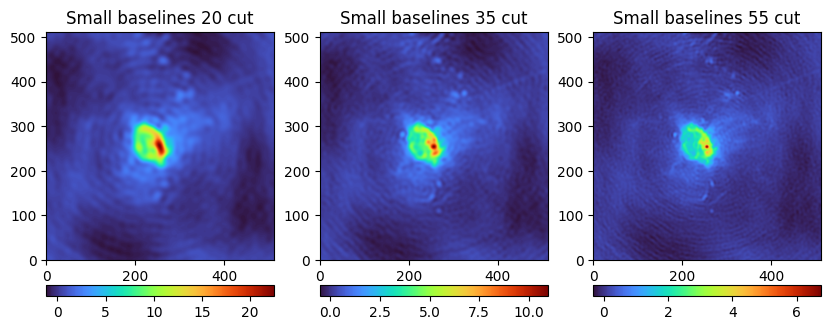

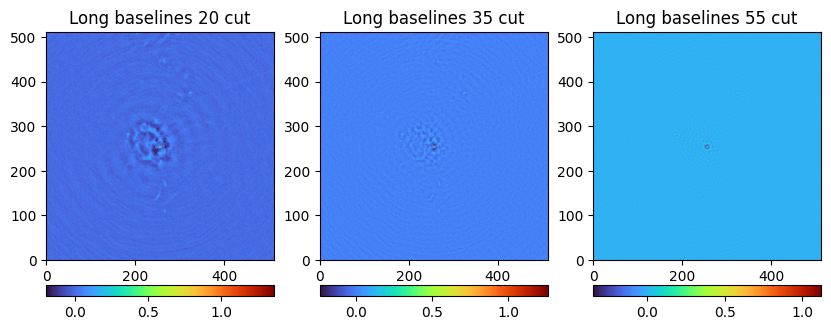

In [10]:
util.plotNImages([dirty_as1.pixels.data[0,0,:,:], dirty_as2.pixels.data[0,0,:,:], \
                     dirty_as3.pixels.data[0,0,:,:]], ["Small baselines 20 cut", "Small baselines 35 cut", \
                                                       "Small baselines 55 cut"], cmap)
util.plotNImages([dirty_al1.pixels.data[0,0,:,:], dirty_al2.pixels.data[0,0,:,:], \
                     dirty_al3.pixels.data[0,0,:,:]], ["Long baselines 20 cut", "Long baselines 35 cut", \
                                                       "Long baselines 55 cut"], cmap)

#### sgr B

In [11]:
%%capture

logging.getLogger().setLevel(logging.CRITICAL)

[val1] = create_visibility_from_ms('../data4/SGRB_long_baselines_15.ms')
[vas1] = create_visibility_from_ms('../data4/SGRB_small_baselines_25.ms')
[val2] = create_visibility_from_ms('../data4/SGRB_long_baselines_30.ms')
[vas2] = create_visibility_from_ms('../data4/SGRB_small_baselines_40.ms')
[val3] = create_visibility_from_ms('../data4/SGRB_long_baselines_50.ms')
[vas3] = create_visibility_from_ms('../data4/SGRB_small_baselines_60.ms')

dirty_al1, psf_al1 = residual.dirty_psf_from_visibilities(val1,cell_size,npix=512,weighting="uniform")
dirty_as1, psf_as1 = residual.dirty_psf_from_visibilities(vas1,cell_size,npix=512,weighting="uniform")
dirty_al2, psf_al2 = residual.dirty_psf_from_visibilities(val2,cell_size,npix=512,weighting="uniform")
dirty_as2, psf_as2 = residual.dirty_psf_from_visibilities(vas2,cell_size,npix=512,weighting="uniform")
dirty_al3, psf_al3 = residual.dirty_psf_from_visibilities(val3,cell_size,npix=512,weighting="uniform")
dirty_as3, psf_as3 = residual.dirty_psf_from_visibilities(vas3,cell_size,npix=512,weighting="uniform")

util.tofits(psf_as1.pixels.data[0, 0, :, :], "../data/SGRB_low25_psf.fits")
util.tofits(dirty_as1.pixels.data[0, 0, :, :], "../data/SGRB_low25_dirty.fits")
util.tofits(psf_as2.pixels.data[0, 0, :, :], "../data/SGRB_low40_psf.fits")
util.tofits(dirty_as2.pixels.data[0, 0, :, :], "../data/SGRB_low40_dirty.fits")
util.tofits(psf_as3.pixels.data[0, 0, :, :], "../data/SGRB_low60_psf.fits")
util.tofits(dirty_as3.pixels.data[0, 0, :, :], "../data/SGRB_low60_dirty.fits")

util.tofits(psf_al1.pixels.data[0, 0, :, :], "../data/SGRB_high15_psf.fits")
util.tofits(dirty_al1.pixels.data[0, 0, :, :], "../data/SGRB_high15_dirty.fits")
util.tofits(psf_al2.pixels.data[0, 0, :, :], "../data/SGRB_high30_psf.fits")
util.tofits(dirty_al2.pixels.data[0, 0, :, :], "../data/SGRB_high30_dirty.fits")
util.tofits(psf_al3.pixels.data[0, 0, :, :], "../data/SGRB_high50_psf.fits")
util.tofits(dirty_al3.pixels.data[0, 0, :, :], "../data/SGRB_high50_dirty.fits")


logging.getLogger().setLevel(logging.NOTSET)

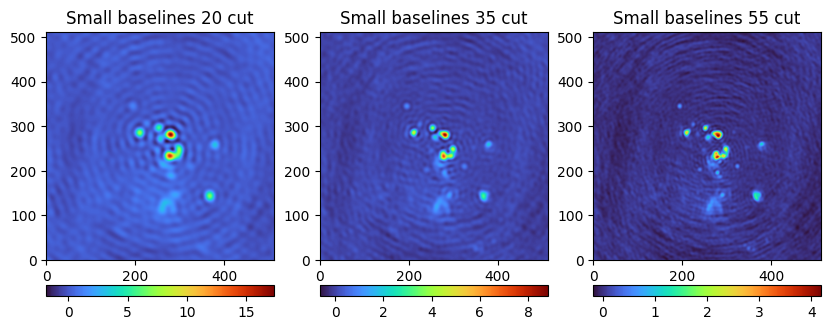

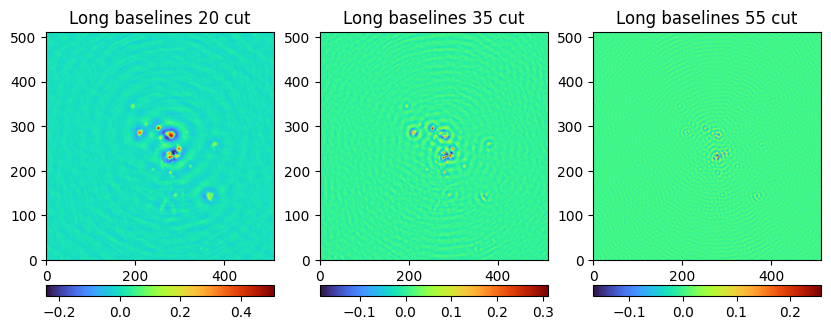

In [12]:
util.plotNImages([dirty_as1.pixels.data[0,0,:,:], dirty_as2.pixels.data[0,0,:,:], \
                     dirty_as3.pixels.data[0,0,:,:]], ["Small baselines 20 cut", "Small baselines 35 cut", \
                                                       "Small baselines 55 cut"], cmap)
util.plotNImages([dirty_al1.pixels.data[0,0,:,:], dirty_al2.pixels.data[0,0,:,:], \
                     dirty_al3.pixels.data[0,0,:,:]], ["Long baselines 20 cut", "Long baselines 35 cut", \
                                                       "Long baselines 55 cut"], cmap)

#### sgr C

In [13]:
%%capture

logging.getLogger().setLevel(logging.CRITICAL)

[val1] = create_visibility_from_ms('../data4/SGRC_long_baselines_15.ms')
[vas1] = create_visibility_from_ms('../data4/SGRC_small_baselines_25.ms')
[val2] = create_visibility_from_ms('../data4/SGRC_long_baselines_30.ms')
[vas2] = create_visibility_from_ms('../data4/SGRC_small_baselines_40.ms')
[val3] = create_visibility_from_ms('../data4/SGRC_long_baselines_50.ms')
[vas3] = create_visibility_from_ms('../data4/SGRC_small_baselines_60.ms')

dirty_al1, psf_al1 = residual.dirty_psf_from_visibilities(val1,cell_size,npix=512,weighting="uniform")
dirty_as1, psf_as1 = residual.dirty_psf_from_visibilities(vas1,cell_size,npix=512,weighting="uniform")
dirty_al2, psf_al2 = residual.dirty_psf_from_visibilities(val2,cell_size,npix=512,weighting="uniform")
dirty_as2, psf_as2 = residual.dirty_psf_from_visibilities(vas2,cell_size,npix=512,weighting="uniform")
dirty_al3, psf_al3 = residual.dirty_psf_from_visibilities(val3,cell_size,npix=512,weighting="uniform")
dirty_as3, psf_as3 = residual.dirty_psf_from_visibilities(vas3,cell_size,npix=512,weighting="uniform")

util.tofits(psf_as1.pixels.data[0, 0, :, :], "../data/SGRC_low25_psf.fits")
util.tofits(dirty_as1.pixels.data[0, 0, :, :], "../data/SGRC_low25_dirty.fits")
util.tofits(psf_as2.pixels.data[0, 0, :, :], "../data/SGRC_low40_psf.fits")
util.tofits(dirty_as2.pixels.data[0, 0, :, :], "../data/SGRC_low40_dirty.fits")
util.tofits(psf_as3.pixels.data[0, 0, :, :], "../data/SGRC_low60_psf.fits")
util.tofits(dirty_as3.pixels.data[0, 0, :, :], "../data/SGRC_low60_dirty.fits")

util.tofits(psf_al1.pixels.data[0, 0, :, :], "../data/SGRC_high15_psf.fits")
util.tofits(dirty_al1.pixels.data[0, 0, :, :], "../data/SGRC_high15_dirty.fits")
util.tofits(psf_al2.pixels.data[0, 0, :, :], "../data/SGRC_high30_psf.fits")
util.tofits(dirty_al2.pixels.data[0, 0, :, :], "../data/SGRC_high30_dirty.fits")
util.tofits(psf_al3.pixels.data[0, 0, :, :], "../data/SGRC_high50_psf.fits")
util.tofits(dirty_al3.pixels.data[0, 0, :, :], "../data/SGRC_high50_dirty.fits")

logging.getLogger().setLevel(logging.NOTSET)

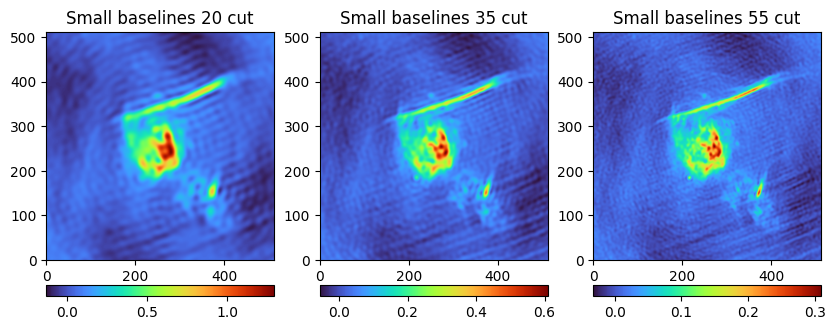

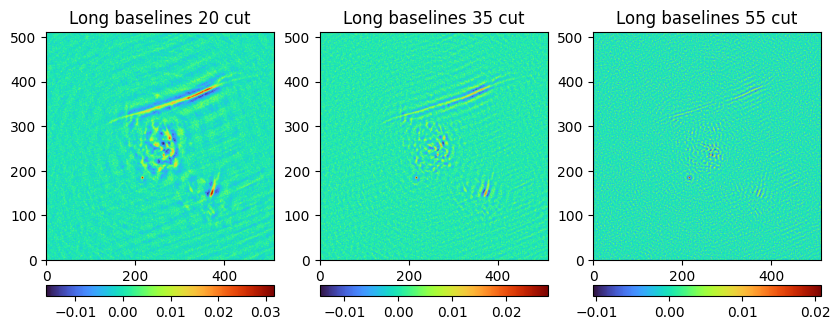

In [14]:
util.plotNImages([dirty_as1.pixels.data[0,0,:,:], dirty_as2.pixels.data[0,0,:,:], \
                     dirty_as3.pixels.data[0,0,:,:]], ["Small baselines 20 cut", "Small baselines 35 cut", \
                                                       "Small baselines 55 cut"], cmap)
util.plotNImages([dirty_al1.pixels.data[0,0,:,:], dirty_al2.pixels.data[0,0,:,:], \
                     dirty_al3.pixels.data[0,0,:,:]], ["Long baselines 20 cut", "Long baselines 35 cut", \
                                                       "Long baselines 55 cut"], cmap)

## Simulations for construction accuracy across different cuts

In [17]:
gts = [util.fromfits("../data/SGRA_full_gt.fits"), util.fromfits("../data/SGRB_full_gt.fits"), \
       util.fromfits("../data/SGRC_full_gt.fits")]

cuts = [20, 35, 55]
hws = [5, 3, 1]
dataset_names = ["Sgr A", "Sgr B2", "Sgr C"]
actual_names = ["SGRA", "SGRB", "SGRC"]

data = []

for i, dataset in enumerate(actual_names):
    curr_data = [dataset]
    for cut in cuts:
        for hw in hws:
            filename = "../results/cut_results/" + dataset + "/" + str(cut) + "/" + str(hw) + "hw/high/" + \
                dataset + "_long_baselines_" + str(cut - hw) + "_nmoment4_cip_deconvolved.fits"
            recon = util.fromfits(filename)
            psnr = evaluation.compute_snr(gts[i], recon)
            curr_data.append(psnr)
            
    data.append(curr_data)

In [18]:
pd.DataFrame(data, columns=["Dataset", "$\ell=20$, $\delta=5$", "$\ell=20$, $\delta=3$", "$\ell=20$, $\delta=1$", \
        "$\ell=35$, $\delta=5$", "$\ell=35$, $\delta=3$", "$\ell=35$, $\delta=1$", \
        "$\ell=55$, $\delta=5$", "$\ell=55$, $\delta=3$", "$\ell=55$, $\delta=1$"])

,Dataset,"$\ell=20$, $\delta=5$","$\ell=20$, $\delta=3$","$\ell=20$, $\delta=1$","$\ell=35$, $\delta=5$","$\ell=35$, $\delta=3$","$\ell=35$, $\delta=1$","$\ell=55$, $\delta=5$","$\ell=55$, $\delta=3$","$\ell=55$, $\delta=1$"
0,SGRA,10.835346,11.376938,11.280979,10.736743,11.053151,11.271863,10.979751,10.828728,10.747182
1,SGRB,10.414734,10.559547,10.270310,10.629569,10.894255,11.048190,11.573429,11.382826,11.307002
2,SGRC,9.161448,9.600902,9.500792,9.571808,9.834182,9.856256,9.582745,9.409331,9.313941


### Test to check how much estimating $\sigma^2$ and $\eta^2$ impacts PSNR

In [27]:
%%capture
logging.getLogger().setLevel(logging.CRITICAL)

if runtests:
    num_maj_cycles = 5
    initial_lambda = 0.05
    lmul = 2
    ell = 20
    delta = 5
    dataset = "SGRA"
    full_cellsize = 0.00001849451
    
    [vl] = create_visibility_from_ms('../data4/' + dataset + '_long_baselines_' + str(ell - delta) + '.ms')
    initial_low_name = "../results/cut_results/" + dataset + "/" + str(ell) + "/" + str(delta) + "hw/low/" + \
        dataset + "_small_baselines_" + str(ell + delta) + "_nmoment4_cip_deconvolved.fits"

    dirty, psf = residual.dirty_psf_from_visibilities(vl, full_cellsize, npix=512, weighting="uniform")
    dirty = dirty.pixels.data[0, 0, :, :]
    psf = psf.pixels.data[0, 0, :, :]
    final_deconvolved = numpy.zeros(dirty.shape)

    low_in = lr_images[0].fits.open(initial_low_name)
    while len(low_in.shape) > 2:
        low_in = low_in[0]

    vis_noise = 4.262045e-06
    recon_noise = 1.557855e-09

    for maj_iteration in range(0, num_maj_cycles):
        deconv = deconvms(dirty, psf, low_in, niter, wavelet_type_idx, maj_iteration, initial_lambda, lmul, \
                            cut_center=ell, cut_halfwidth=delta, lowin=low_in, vis_variance=vis_noise, \
                            recon_variance=recon_noise)
        final_deconvolved += deconv
        low_in = low_in - deconv

        #de/gridding
        im.pixels.data = [[final_deconvolved]]
        vdec = vl.copy(deep=True)
        vdec = predict_ng(vdec,im,context='2d')
        vres = subtract_visibility(vl, vdec)
        model = create_image_from_visibility(vres,cellsize=full_cellsize,npixel=512)
        dirty, sumwt = invert_ng(vres, model, context='2d')
        dirty = dirty.pixels.data

        while len(dirty.shape) > 2:
            dirty = dirty[0]

    psnr = evaluation.compute_snr(util.fromfits("data/SGRC_full_gt.fits"), final_deconvolved)

logging.getLogger().setLevel(logging.NOTSET)

In [18]:
%%capture
logging.getLogger().setLevel(logging.CRITICAL)

if runtests:
    num_maj_cycles = 5
    initial_lambda = 0.05
    lmul = 2
    ell = 20
    delta = 5
    dataset = "SGRA"
    full_cellsize = 0.00001849451
    
    [vl] = create_visibility_from_ms('../data4/' + dataset + '_long_baselines_' + str(ell - delta) + '.ms')
    initial_low_name = "../results/cut_results/" + dataset + "/" + str(ell) + "/" + str(delta) + "hw/low/" + \
        dataset + "_small_baselines_" + str(ell + delta) + "_nmoment4_cip_deconvolved.fits"

    dirty, psf = dirty_psf_from_visibilities(vl, full_cellsize, npix=512, weighting="uniform")
    dirty = dirty.pixels.data[0, 0, :, :]
    psf = psf.pixels.data[0, 0, :, :]
    final_deconvolved = numpy.zeros(dirty.shape)

    low_in = lr_images[0].fits.open(initial_low_name)
    while len(low_in.shape) > 2:
        low_in = low_in[0]

    for maj_iteration in range(0, num_maj_cycles):
        deconv = deconvms(dirty, psf, low_in, niter, wavelet_type_idx, maj_iteration, initial_lambda, lmul, \
                            cut_center=ell, cut_halfwidth=delta, lowin=low_in, recon_variance_factor=1000)
        final_deconvolved += deconv
        low_in = low_in - deconv

        #de/gridding
        im.pixels.data = [[final_deconvolved]]
        vdec = vl.copy(deep=True)
        vdec = predict_ng(vdec,im,context='2d')
        vres = subtract_visibility(vl, vdec)
        model = create_image_from_visibility(vres,cellsize=full_cellsize,npixel=512)
        dirty, sumwt = invert_ng(vres, model, context='2d')
        dirty = dirty.pixels.data

        while len(dirty.shape) > 2:
            dirty = dirty[0]

    psnr = evaluation.compute_snr(util.fromfits("../data/SGRC_full_gt.fits"), final_deconvolved)

logging.getLogger().setLevel(logging.NOTSET)

In [19]:
if runtests:
    util.plotNImages([final_deconvolved, final_deconvolved_auto], ["PSNR = " + str(psnr), "PSNR = " + str(psnr_auto)], cmap)

## Evaluation of PSNRs across the major cycles for both Low and Multistep

In [29]:
gts_multistep = [util.fromfits("../data/SGRA_full_gt.fits"), util.fromfits("../data/SGRB_full_gt.fits"), \
       util.fromfits("../data/SGRC_full_gt.fits")]

gts_low = [[[util.fromfits("../data/SGRA_low25_gt.fits"), util.fromfits("../data/SGRA_low23_gt.fits"), util.fromfits("../data/SGRA_low21_gt.fits")], \
            [util.fromfits("../data/SGRA_low40_gt.fits"), util.fromfits("../data/SGRA_low38_gt.fits"), util.fromfits("../data/SGRA_low36_gt.fits")], \
            [util.fromfits("../data/SGRA_low60_gt.fits"), util.fromfits("../data/SGRA_low58_gt.fits"), util.fromfits("../data/SGRA_low56_gt.fits")]], \
            [[util.fromfits("../data/SGRB_low25_gt.fits"), util.fromfits("../data/SGRB_low23_gt.fits"), util.fromfits("../data/SGRB_low21_gt.fits")], \
            [util.fromfits("../data/SGRB_low40_gt.fits"), util.fromfits("../data/SGRB_low38_gt.fits"), util.fromfits("../data/SGRB_low36_gt.fits")], \
            [util.fromfits("../data/SGRB_low60_gt.fits"), util.fromfits("../data/SGRB_low58_gt.fits"), util.fromfits("../data/SGRB_low56_gt.fits")]], \
            [[util.fromfits("../data/SGRC_low25_gt.fits"), util.fromfits("../data/SGRC_low23_gt.fits"), util.fromfits("../data/SGRC_low21_gt.fits")], \
            [util.fromfits("../data/SGRC_low40_gt.fits"), util.fromfits("../data/SGRC_low38_gt.fits"), util.fromfits("../data/SGRC_low36_gt.fits")], \
            [util.fromfits("../data/SGRC_low60_gt.fits"), util.fromfits("../data/SGRC_low58_gt.fits"), util.fromfits("../data/SGRC_low56_gt.fits")]]]

cuts = [20, 35, 55]
hws = [5, 3, 1]
dataset_names = ["Sgr A", "Sgr B2", "Sgr C"]
actual_names = ["SGRA", "SGRB", "SGRC"]

data_low = []
data_high = []

noiseless = False
weight = "uniform"
lambdam = 2

for i, dataset in enumerate(actual_names):
    high_gt = gts_multistep[i]
    for j, cut in enumerate(cuts):
        for k, hw in enumerate(hws):
            curr_data_low = [dataset + " " + str(cut) + " " + str(hw)]
            curr_data_high = [dataset + " " + str(cut) + " " + str(hw)]
            
            path = "../results/noiseless_cut_results/" + weighting + "/" + dataset + "/" + str(cut) + "/" + str(hw) + \
                "hw/high/lambda_m" + str(lmult) + "/" if noiseless else \
                "../results/cut_results/" + dataset + "/" + str(cut) + "/" + str(hw) + "hw/bphigh/lambda_m" + str(lambdam) + "/"
            
            low_gt = gts_low[i][j][k]
            
            curr_deconv_low = None
            curr_deconv_high = None
            for maj_iter in range(0, 5):
                high_filename = path + "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
                low_filename = "../results/cut_results/" + dataset + "/" + str(cut) + "/" + str(hw) + "hw/low/" + \
                    "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
                deconv_low = util.fromfits(low_filename)
                deconv_high = util.fromfits(high_filename)
                
                if curr_deconv_low is None:
                    curr_deconv_low = deconv_low
                else:
                    curr_deconv_low += deconv_low
                
                if curr_deconv_high is None:
                    curr_deconv_high = deconv_high
                else:
                    curr_deconv_high += deconv_high
                
                psnr_low = evaluation.compute_snr(low_gt, curr_deconv_low)
                psnr_high = evaluation.compute_snr(high_gt, curr_deconv_high)
                #psnr_low = helpers.compute_rmse(low_gt, curr_deconv_low)
                #psnr_high = helpers.compute_rmse(high_gt, curr_deconv_high)
                dirtyfn = path + "dirty_iteration_" + str(maj_iter) + "_channel_0.fits"
                high_dirty = util.fromfits(dirtyfn)
                #psnr_high = numpy.linalg.norm(high_dirty)
                curr_data_low.append(psnr_low)
                curr_data_high.append(psnr_high)
                
                #if maj_iter == 4:
                #    print(psnr_high)
                #    helpers.plotNImages([curr_deconv_high, high_gt], ["", ""], cmap=cmap, same_scale=True)
            
            data_low.append(curr_data_low)
            data_high.append(curr_data_high)

### Low

In [30]:
pd.DataFrame(data_low, columns=["Dataset", "1", "2", "3", "4", "5"])

,Dataset,1,2,3,4,5
0,SGRA 20 5,7.868691,10.826435,12.124501,12.779703,12.933220
1,SGRA 20 3,7.822193,10.649821,12.365950,13.634438,14.575970
2,SGRA 20 1,7.892509,10.811887,12.488335,13.645274,14.369115
3,SGRA 35 5,7.748034,10.427249,11.413961,12.038729,12.189237
4,SGRA 35 3,7.889055,10.702056,11.943311,12.749844,13.095742
5,SGRA 35 1,7.915350,10.809227,12.374405,13.484942,14.166643
6,SGRA 55 5,7.909521,10.787168,12.093298,12.910655,13.275766
7,SGRA 55 3,7.790249,10.580756,11.759511,12.562767,12.906099
8,SGRA 55 1,7.908697,10.728419,11.867201,12.610089,12.926100
9,SGRB 20 5,7.180386,9.401610,10.027414,10.004053,10.445597


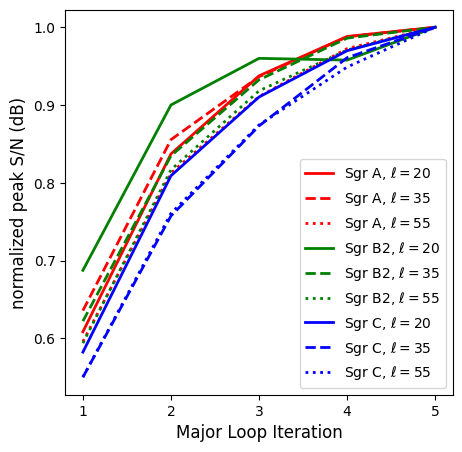

In [31]:
matplotlib.rcParams['figure.figsize'] = [5, 5]
from functools import partial

colours = ['r', 'r', 'r', 'g', 'g', 'g', 'b', 'b', 'b']
styles = ['-', '--', ':', '-', '--', ':', '-', '--', ':']
labels = ["Sgr A, $\ell=20$", "Sgr A, $\ell=35$", "Sgr A, $\ell=55$", \
          "Sgr B2, $\ell=20$", "Sgr B2, $\ell=35$", "Sgr B2, $\ell=55$", \
          "Sgr C, $\ell=20$", "Sgr C, $\ell=35$", "Sgr C, $\ell=55$"]

for i, data in enumerate(data_low[::3]):
    cleaned_data = data[1:]
    norm_factor = numpy.max(cleaned_data)
    cleaned_data = [x / norm_factor for x in cleaned_data]

    plt.plot(range(1, 6), cleaned_data, c=colours[i], linestyle=styles[i], label=labels[i], lw=2)

plt.xticks([1,2,3,4,5])
    
plt.legend(loc="lower right", fontsize=10)
#plt.legend(loc="upper right", fontsize=10, ncol=2)
#plt.yscale('function', functions=(partial(numpy.power, 2.0), partial(numpy.emath.logn, 2.0)))
    
plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("normalized peak S/N (dB)", fontsize=12)
plt.savefig("../figures/low_majcycle_conv.png", bbox_inches='tight')

### Multistep

In [32]:
pd.DataFrame(data_high, columns=["Dataset", "1", "2", "3", "4", "5"])

,Dataset,1,2,3,4,5
0,SGRA 20 5,10.800842,10.835346,10.835346,10.835346,10.835346
1,SGRA 20 3,11.344304,11.376938,11.376938,11.376938,11.376938
2,SGRA 20 1,11.256612,11.280979,11.280979,11.280979,11.280979
3,SGRA 35 5,10.732105,10.736743,10.736743,10.736743,10.736743
4,SGRA 35 3,11.048757,11.053151,11.053151,11.053151,11.053151
5,SGRA 35 1,11.268180,11.271863,11.271863,11.271863,11.271863
6,SGRA 55 5,10.979951,10.979751,10.979751,10.979751,10.979751
7,SGRA 55 3,10.829113,10.828726,10.828726,10.828726,10.828726
8,SGRA 55 1,10.747953,10.747158,10.747158,10.747158,10.747158
9,SGRB 20 5,9.186776,10.414337,10.414734,10.414734,10.414734


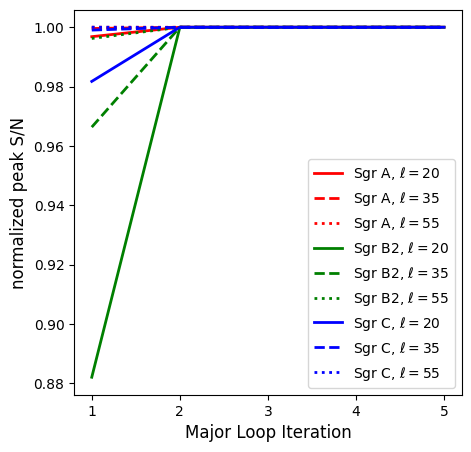

In [33]:
colours = ['r', 'r', 'r', 'g', 'g', 'g', 'b', 'b', 'b']
styles = ['-', '--', ':', '-', '--', ':', '-', '--', ':']
labels = ["Sgr A, $\ell=20$", "Sgr A, $\ell=35$", "Sgr A, $\ell=55$", \
         "Sgr B2, $\ell=20$", "Sgr B2, $\ell=35$", "Sgr B2, $\ell=55$", \
         "Sgr C, $\ell=20$", "Sgr C, $\ell=35$", "Sgr C, $\ell=55$"]

for i, data in enumerate(data_high[::3]):
    cleaned_data = data[1:]
    norm_factor = numpy.max(cleaned_data)
    cleaned_data = [x / norm_factor for x in cleaned_data]
    plt.plot(range(1, 6), cleaned_data, c=colours[i], linestyle=styles[i], label=labels[i], lw=2)
    
plt.legend(loc="lower right",  fontsize=10)
plt.xticks([1,2,3,4,5])

plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("normalized peak S/N", fontsize=12)
plt.savefig("../figures/high_majcycle_conv.png", bbox_inches='tight')

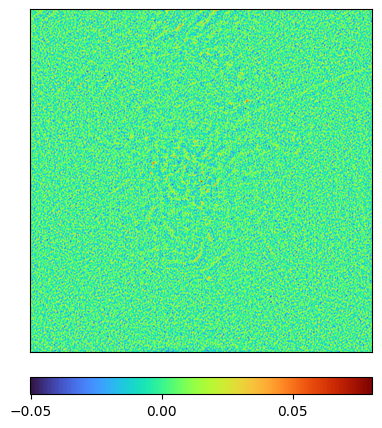

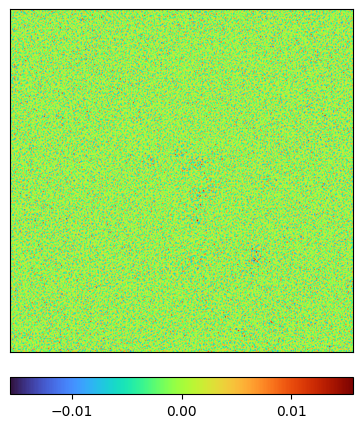

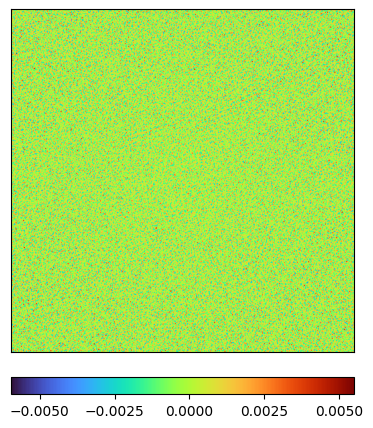

In [34]:
aresid = util.fromfits("../results/cut_results/SGRA/20/5hw/high/dirty_iteration_2_channel_0.fits")
bresid = util.fromfits("../results/cut_results/SGRB/55/5hw/high/dirty_iteration_2_channel_0.fits")
cresid = util.fromfits("../results/cut_results/SGRC/55/5hw/high/dirty_iteration_2_channel_0.fits")

util.plotNImages([aresid], [""], output_file="../figures/aresid_high.png", cmap=cmap, hide_ticks=True)
util.plotNImages([bresid], [""], output_file="../figures/bresid_high.png", cmap=cmap, hide_ticks=True)
util.plotNImages([cresid], [""], output_file="../figures/cresid_high.png", cmap=cmap, hide_ticks=True)

## Evaluation of convergence within FISTA for low and high

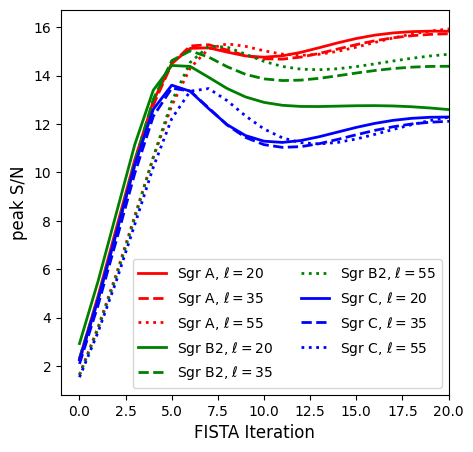

In [35]:
cuts = [20, 35, 55]
actual_names = ["SGRA", "SGRB", "SGRC"]
matplotlib.rcParams['figure.figsize'] = [5, 5]

colours = ['r', 'g', 'b']
lstyles = ['-', '--', ':']
labels = [["Sgr A, $\ell=20$", "Sgr A, $\ell=35$", "Sgr A, $\ell=55$"], \
         ["Sgr B2, $\ell=20$", "Sgr B2, $\ell=35$", "Sgr B2, $\ell=55$"], \
         ["Sgr C, $\ell=20$", "Sgr C, $\ell=35$", "Sgr C, $\ell=55$"]]

for i, dataset in enumerate(actual_names):
    gt = util.fromfits("../data/" + dataset + "_full_gt.fits")
    for j, cut in enumerate(cuts):

        csv_name = "../results/cut_results/fista_convergence/" + dataset + "_low" + str(cut + 5) + ".csv"
        data = util.read_csv(csv_name)
        data = data[1:]
        data = [20 * numpy.log10(numpy.linalg.norm(gt) / numpy.sqrt(float(x))) for x in data]
        
        plt.plot(range(0, len(data)), data, c=colours[i], linestyle=styles[j], label=labels[i][j], lw=2)

plt.legend(loc="lower right", fontsize=10, ncol=2)
#plt.yscale('log')
#plt.xscale('log')
plt.xlim((-1, 20))
plt.xlabel("FISTA Iteration", fontsize=12)
plt.ylabel("peak S/N", fontsize=12)
plt.savefig("../figures/low_fista_conv.png", bbox_inches='tight')
        

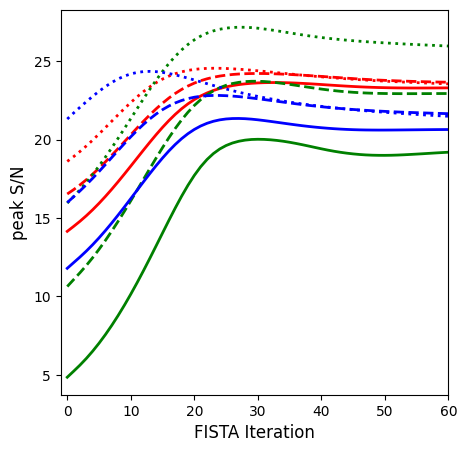

In [36]:
cuts = [20, 35, 55]
actual_names = ["SGRA", "SGRB", "SGRC"]
deltas = [5, 3, 1]

colours = ['r', 'g', 'b']
lstyles = ['-', '--', ':']
labels = [["Sgr A, $\ell=20$", "Sgr A, $\ell=35$", "Sgr A, $\ell=55$"], \
         ["Sgr B2, $\ell=20$", "Sgr B2, $\ell=35$", "Sgr B2, $\ell=55$"], \
         ["Sgr C, $\ell=20$", "Sgr C, $\ell=35$", "Sgr C, $\ell=55$"]]

gts_multistep = [util.fromfits("../data/SGRA_full_gt.fits"), util.fromfits("../data/SGRB_full_gt.fits"), \
       util.fromfits("../data/SGRC_full_gt.fits")]

for i, dataset in enumerate(actual_names):
    gt = util.fromfits("../data/" + dataset + "_full_gt.fits")
    high_gt = gts_multistep[0]
    for j, cut in enumerate(cuts):
        csv_name = "../results/cut_results/fista_convergence/" + dataset + "_high" + str(cut + 5) + ".csv"
        data = util.read_csv(csv_name)
        data = data[1:]
        data = [20 * numpy.log10(numpy.linalg.norm(gt) / numpy.sqrt(float(x))) for x in data]
        
        plt.plot(range(0, len(data)), data, c=colours[i], linestyle=styles[j], label=labels[i][j], lw=2)

#plt.legend(loc="upper right", fontsize=10, ncol=2)
#plt.yscale('log')
#plt.xscale('log')
plt.xlabel("FISTA Iteration", fontsize=12)
plt.ylabel("peak S/N", fontsize=12)
plt.xlim((-1, 60))
plt.savefig("../figures/high_fista_conv.png", bbox_inches='tight')
        

## Comparison against full reconstruction

### Accuracy of final full constructions

In [37]:
from visibilities import compute_residual

[va] = create_visibility_from_ms('../data/SGRA.ms')
[vb] = create_visibility_from_ms('../data/SGRB.ms')
[vc] = create_visibility_from_ms('../data/SGRC.ms')

#done for all three mainly for weight computation
dirtya, psfa = residual.dirty_psf_from_visibilities(va,cell_size,npix=512,weighting="uniform")
dirtyb, psfb = residual.dirty_psf_from_visibilities(vb,cell_size,npix=512,weighting="uniform")
dirtyc, psfc = residual.dirty_psf_from_visibilities(vc,cell_size,npix=512,weighting="uniform")

create_visibility_from_ms: {'type': 'Measurement Set', 'subType': '', 'readme': 'This is a MeasurementSet Table holding measurements from a Telescope\n'}
create_visibility_from_ms: Reading unique fields [0], unique data descriptions [0]
create_visibility_from_ms: Found 249600 rows
create_visibility_from_ms: Found 1 channels
create_visibility_from_ms: Reading all 1 channels
create_visibility_from_ms: Observation from 2000-01-01 17:37:07.746 to 2000-01-01 21:35:07.746
create_visibility_from_ms: {'type': 'Measurement Set', 'subType': '', 'readme': 'This is a MeasurementSet Table holding measurements from a Telescope\n'}
create_visibility_from_ms: Reading unique fields [0], unique data descriptions [0]
create_visibility_from_ms: Found 249600 rows
create_visibility_from_ms: Found 1 channels
create_visibility_from_ms: Reading all 1 channels
create_visibility_from_ms: Observation from 2000-01-01 17:36:23.132 to 2000-01-01 21:34:23.132


/home/sunwang/.local/lib/python3.10/site-packages/ska_sdp_datamodels/visibility/vis_model.py:190: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'baselines' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
  return cls(datavars, coords=coords, attrs=attrs)


create_visibility_from_ms: {'type': 'Measurement Set', 'subType': '', 'readme': 'This is a MeasurementSet Table holding measurements from a Telescope\n'}
create_visibility_from_ms: Reading unique fields [0], unique data descriptions [0]
create_visibility_from_ms: Found 249600 rows
create_visibility_from_ms: Found 1 channels
create_visibility_from_ms: Reading all 1 channels
create_visibility_from_ms: Observation from 2000-01-01 17:37:07.746 to 2000-01-01 21:35:07.746


/home/sunwang/.local/lib/python3.10/site-packages/ska_sdp_datamodels/visibility/vis_model.py:190: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'baselines' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
  return cls(datavars, coords=coords, attrs=attrs)


create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -30.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 radians, 0.00105966 degrees
create_image_from_visibility: image shape is (1, 1, 512, 512)


/home/sunwang/.local/lib/python3.10/site-packages/ska_sdp_datamodels/visibility/vis_model.py:190: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'baselines' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
  return cls(datavars, coords=coords, attrs=attrs)


Model image plate scale (arcsec) is 3.814767e+00
create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -35.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 radians, 0.00105966 degrees
create_image_from_visibility: image shape is (1, 1, 512, 512)
Model image plate scale (arcsec) is 3.814767e+00
create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -30.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cel

In [38]:
sgra_gt = util.fromfits("../data/SGRA_full_gt.fits")
sgrb_gt = util.fromfits("../data/SGRB_full_gt.fits")
sgrc_gt = util.fromfits("../data/SGRC_full_gt.fits")

sgra_deconv = util.fromfits("../results/cut_results/full_recons/SGRA/SGRA_nmoment4_cip_deconvolved.fits")
sgrb_deconv = util.fromfits("../results/cut_results/full_recons/SGRB/SGRB_nmoment4_cip_deconvolved.fits")
sgrc_deconv = util.fromfits("../results/cut_results/full_recons/SGRC/SGRC_nmoment4_cip_deconvolved.fits")

dirtya.pixels.data[0,0,:,:] = sgra_deconv
dirtyb.pixels.data[0,0,:,:] = sgrb_deconv
dirtyc.pixels.data[0,0,:,:] = sgrc_deconv

sgra_resid = compute_residual(dirtya, va, 512, cell_size)
sgrb_resid = compute_residual(dirtyb, vb, 512, cell_size)
sgrc_resid = compute_residual(dirtyc, vc, 512, cell_size)

sgra_snr = evaluation.compute_snr(sgra_gt, sgra_deconv)
sgrb_snr = evaluation.compute_snr(sgrb_gt, sgrb_deconv)
sgrc_snr = evaluation.compute_snr(sgrc_gt, sgrc_deconv)

create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -30.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 radians, 0.00105966 degrees
create_image_from_visibility: image shape is (1, 1, 512, 512)
create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -35.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 ra

In [39]:
sgra_mstep_deconv = util.fromfits("../results/additional_split_results/SGRA/full/SGRA_long_baselines_30_nmoment4_cip_deconvolved.fits")
sgrb_mstep_deconv = util.fromfits("../results/additional_split_results/SGRB/full/SGRB_long_baselines_30_nmoment4_cip_deconvolved.fits")
sgrc_mstep_deconv = util.fromfits("../results/additional_split_results/SGRC/full/SGRC_long_baselines_30_nmoment4_cip_deconvolved.fits")

dirtya.pixels.data[0,0,:,:] = sgra_mstep_deconv
dirtyb.pixels.data[0,0,:,:] = sgrb_mstep_deconv
dirtyc.pixels.data[0,0,:,:] = sgrc_mstep_deconv

sgra_mstep_resid = residual.compute_residual(dirtya, va, 512, cell_size)
sgrb_mstep_resid = residual.compute_residual(dirtyb, vb, 512, cell_size)
sgrc_mstep_resid = residual.compute_residual(dirtyc, vc, 512, cell_size)

sgrams_snr = evaluation.compute_snr(sgra_gt, sgra_mstep_deconv)
sgrbms_snr = evaluation.compute_snr(sgrb_gt, sgrb_mstep_deconv)
sgrcms_snr = evaluation.compute_snr(sgrc_gt, sgrc_mstep_deconv)

create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -30.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 radians, 0.00105966 degrees
create_image_from_visibility: image shape is (1, 1, 512, 512)
create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -35.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 ra

In [40]:
from ska_sdp_func_python.image import fit_psf
from ska_sdp_func_python.image.operations import convert_clean_beam_to_pixels
from astropy.convolution import Gaussian2DKernel, convolve_fft

clean_beam = fit_psf(psfa)
beam_pixels = convert_clean_beam_to_pixels(dirtya, clean_beam)
gk = Gaussian2DKernel(x_stddev=beam_pixels[0], y_stddev=beam_pixels[1], theta=beam_pixels[2])
norm = 2.0 * numpy.pi * beam_pixels[0] * beam_pixels[1]

In [41]:
sgra_msclean_deconv = util.fromfits("../results/msclean/SGRA/SGRA_nmoment4_cip_deconvolved.fits")
sgrb_msclean_deconv = util.fromfits("../results/msclean/SGRB/SGRB_nmoment4_cip_deconvolved.fits")
sgrc_msclean_deconv = util.fromfits("../results/msclean/SGRC/SGRC_nmoment4_cip_deconvolved.fits")

dirtya.pixels.data[0,0,:,:] = sgra_msclean_deconv
dirtyb.pixels.data[0,0,:,:] = sgrb_msclean_deconv
dirtyc.pixels.data[0,0,:,:] = sgrc_msclean_deconv

sgra_msclean_resid = compute_residual(dirtya, va, 512, cell_size)
sgrb_msclean_resid = compute_residual(dirtyb, vb, 512, cell_size)
sgrc_msclean_resid = compute_residual(dirtyc, vc, 512, cell_size)

sgra_msclean_deconv = convolve_fft(sgra_msclean_deconv, gk, normalize_kernel=False, allow_huge=True, boundary="wrap")
sgrb_msclean_deconv = convolve_fft(sgrb_msclean_deconv, gk, normalize_kernel=False, allow_huge=True, boundary="wrap")
sgrc_msclean_deconv = convolve_fft(sgrc_msclean_deconv, gk, normalize_kernel=False, allow_huge=True, boundary="wrap")

sgramsclean_snr = evaluation.compute_snr(sgra_gt, sgra_msclean_deconv)
sgrbmsclean_snr = evaluation.compute_snr(sgrb_gt, sgrb_msclean_deconv)
sgrcmsclean_snr = evaluation.compute_snr(sgrc_gt, sgrc_msclean_deconv)

create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -30.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 radians, 0.00105966 degrees
create_image_from_visibility: image shape is (1, 1, 512, 512)
create_image_from_visibility: Parsing parameters to get definition of WCS
create_image_from_visibility: Defining single channel Image at <SkyCoord (ICRS): (ra, dec) in deg
    (56., -35.)>, starting frequency 1000000000.0 Hz, and bandwidth 1000000.0 Hz
create_image_from_visibility: uvmax = 24331.536075 wavelengths
create_image_from_visibility: Critical cellsize = 0.000021 radians, 0.001177 degrees
create_image_from_visibility: Cellsize = 1.84945e-05 ra

10.352854612649791
11.2038203723199
9.26784089825949
11.213608556786827


/home/sunwang/radio-imaging/src/radioimaging/util/util.py:137: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, num_images)


11.234233837163396
10.080029959950638
10.894688093856871
11.066806076093066
9.231176414505779


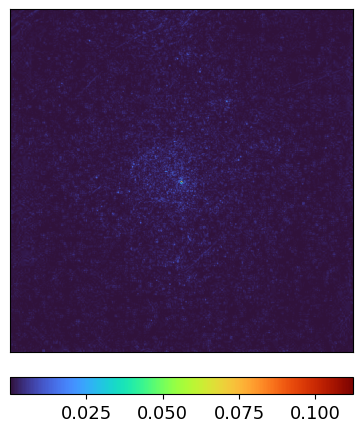

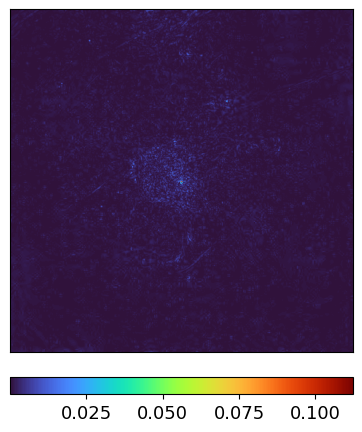

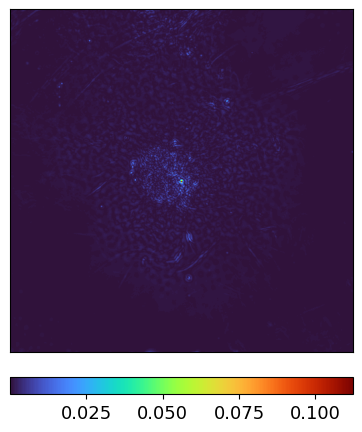

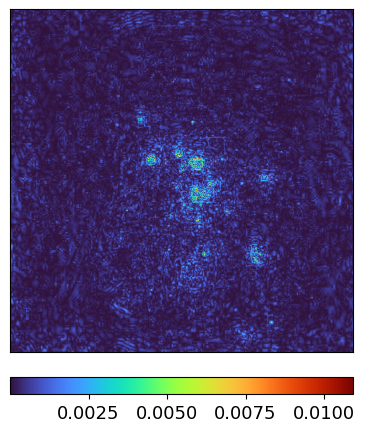

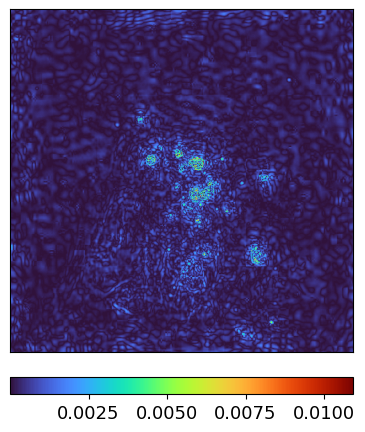

...

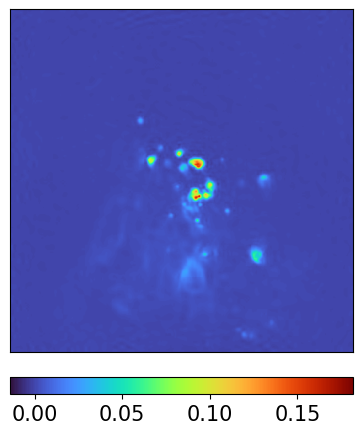

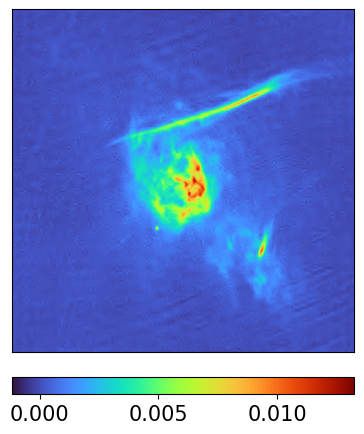

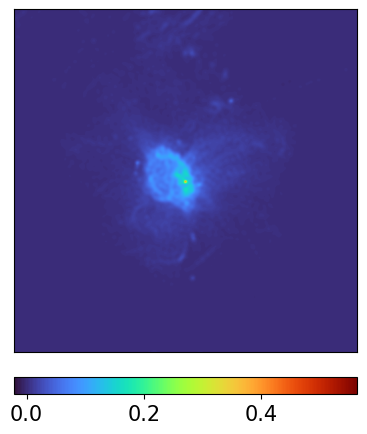

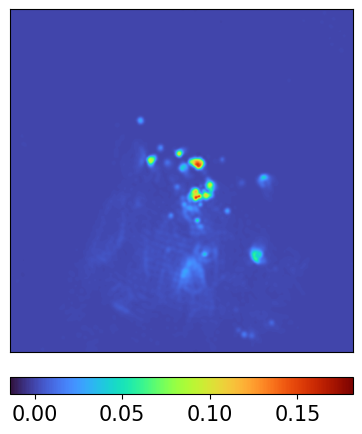

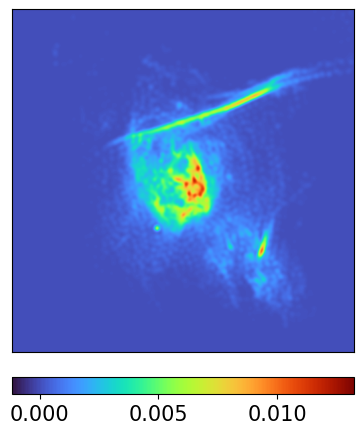

In [43]:
adif = numpy.abs(sgra_gt - sgra_deconv)
amsdif = numpy.abs(sgra_gt - sgra_mstep_deconv)
amscleandif = numpy.abs(sgra_gt - sgra_msclean_deconv)
bdif = numpy.abs(sgrb_gt - sgrb_deconv)
bmsdif = numpy.abs(sgrb_gt - sgrb_mstep_deconv)
bmscleandif = numpy.abs(sgrb_gt - sgrb_msclean_deconv)
cdif = numpy.abs(sgrc_gt - sgrc_deconv)
cmsdif = numpy.abs(sgrc_gt - sgrc_mstep_deconv)
cmscleandif = numpy.abs(sgrc_gt - sgrc_msclean_deconv)


util.plotNImages([adif], [""], cmap, scale_mul=0.5, output_file="../figures/full_sgra_abserr.png", same_scale=True, additional_scale_imgs=[amsdif, amscleandif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([amsdif], [""], cmap, scale_mul=0.5, output_file="../figures/mstep_sgra_abserr.png", same_scale=True, additional_scale_imgs=[adif, amscleandif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([amscleandif], [""], cmap, scale_mul=0.5, output_file="../figures/msclean_sgra_abserr.png", same_scale=True, additional_scale_imgs=[adif, amsdif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([bdif], [""], cmap, scale_mul=0.5, output_file="../figures/full_sgrb_abserr.png", same_scale=True, additional_scale_imgs=[bmsdif, bmscleandif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([bmsdif], [""], cmap, scale_mul=0.5, output_file="../figures/mstep_sgrb_abserr.png", same_scale=True, additional_scale_imgs=[bdif, bmscleandif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([bmscleandif], [""], cmap, scale_mul=0.5, output_file="../figures/msclean_sgrb_abserr.png", same_scale=True, additional_scale_imgs=[bdif, bmsdif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([cdif], [""], cmap, scale_mul=0.5, output_file="../figures/full_sgrc_abserr.png", same_scale=True, additional_scale_imgs=[cmsdif, cmscleandif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([cmsdif], [""], cmap, scale_mul=0.5, output_file="../figures/mstep_sgrc_abserr.png", same_scale=True, additional_scale_imgs=[cdif, cmscleandif], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([cmscleandif], [""], cmap, scale_mul=0.5, output_file="../figures/msclean_sgrc_abserr.png", same_scale=True, additional_scale_imgs=[cdif, cmsdif], hide_ticks=True, cbar_labelsize=13)


sgra_resid = numpy.abs(sgra_resid.pixels.data[0,0,:,:])
sgrb_resid = numpy.abs(sgrb_resid.pixels.data[0,0,:,:])
sgrc_resid = numpy.abs(sgrc_resid.pixels.data[0,0,:,:])
sgra_mstep_resid = numpy.abs(sgra_mstep_resid.pixels.data[0,0,:,:])
sgrb_mstep_resid = numpy.abs(sgrb_mstep_resid.pixels.data[0,0,:,:])
sgrc_mstep_resid = numpy.abs(sgrc_mstep_resid.pixels.data[0,0,:,:])
sgra_msclean_resid = numpy.abs(sgra_msclean_resid.pixels.data[0,0,:,:])
sgrb_msclean_resid = numpy.abs(sgrb_msclean_resid.pixels.data[0,0,:,:])
sgrc_msclean_resid = numpy.abs(sgrc_msclean_resid.pixels.data[0,0,:,:])

util.plotNImages([sgra_resid], [""], cmap, output_file="../figures/full_sgra_resid.png", same_scale=True, additional_scale_imgs=[sgra_mstep_resid, sgra_msclean_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgra_mstep_resid], [""], cmap, output_file="../figures/mstep_sgra_resid.png", same_scale=True, additional_scale_imgs=[sgra_resid, sgra_msclean_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgra_msclean_resid], [""], cmap, output_file="../figures/msclean_sgra_resid.png", same_scale=True, additional_scale_imgs=[sgra_resid, sgra_mstep_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgrb_resid], [""], cmap, output_file="../figures/full_sgrb_resid.png", same_scale=True, additional_scale_imgs=[sgrb_mstep_resid, sgrb_msclean_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgrb_mstep_resid], [""], cmap, output_file="../figures/mstep_sgrb_resid.png", same_scale=True, additional_scale_imgs=[sgrb_resid, sgrb_msclean_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgrb_msclean_resid], [""], cmap, output_file="../figures/msclean_sgrb_resid.png", same_scale=True, additional_scale_imgs=[sgrb_resid, sgrb_mstep_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgrc_resid], [""], cmap, output_file="../figures/full_sgrc_resid.png", same_scale=True, additional_scale_imgs=[sgrc_mstep_resid, sgrc_msclean_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgrc_mstep_resid], [""], cmap, output_file="../figures/mstep_sgrc_resid.png", same_scale=True, additional_scale_imgs=[sgrc_resid, sgrc_msclean_resid], hide_ticks=True, cbar_labelsize=13)
util.plotNImages([sgrc_msclean_resid], [""], cmap, output_file="../figures/msclean_sgrc_resid.png", same_scale=True, additional_scale_imgs=[sgrc_resid, sgrc_mstep_resid], hide_ticks=True, cbar_labelsize=13)


print(sgra_snr)
util.plotNImages([sgra_deconv], [""], cmap, output_file="../figures/full_sgra.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgra_mstep_deconv, sgra_msclean_deconv], cbar_labelsize=15, vpadding=0.01)

print(sgrb_snr)
util.plotNImages([sgrb_deconv], [""], cmap, output_file="../figures/full_sgrb.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgrb_mstep_deconv, sgrb_msclean_deconv], cbar_labelsize=15, vpadding=0.01)

print(sgrc_snr)
util.plotNImages([sgrc_deconv], [""], cmap, output_file="../figures/full_sgrc.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgrc_mstep_deconv, sgrc_msclean_deconv], cbar_labelsize=15)

print(sgrams_snr)
util.plotNImages([sgra_mstep_deconv], [""], cmap, output_file="../figures/mstep_sgra.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgra_deconv, sgra_msclean_deconv], cbar_labelsize=15, vpadding=0.01)

print(sgrbms_snr)
util.plotNImages([sgrb_mstep_deconv], [""], cmap, output_file="../figures/mstep_sgrb.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgrb_deconv, sgrb_msclean_deconv], cbar_labelsize=15, vpadding=0.01)

print(sgrcms_snr)
util.plotNImages([sgrc_mstep_deconv], [""], cmap, output_file="../figures/mstep_sgrc.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgrc_deconv, sgrc_msclean_deconv], cbar_labelsize=15)

print(sgramsclean_snr)
util.plotNImages([sgra_msclean_deconv], [""], cmap, output_file="../figures/msclean_sgra.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgra_deconv, sgra_mstep_deconv], cbar_labelsize=15, vpadding=0.01)

print(sgrbmsclean_snr)
util.plotNImages([sgrb_msclean_deconv], [""], cmap, output_file="../figures/msclean_sgrb.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgrb_deconv, sgrb_mstep_deconv], cbar_labelsize=15, vpadding=0.01)

print(sgrcmsclean_snr)
util.plotNImages([sgrc_msclean_deconv], [""], cmap, output_file="../figures/msclean_sgrc.png", hide_ticks=True, same_scale=True, additional_scale_imgs=[sgrc_deconv, sgrc_mstep_deconv], cbar_labelsize=15)

In [44]:
colours = ['r', 'g', 'b']
datasets = ["Sgr A", "Sgr B2", "Sgr C"]
actual_datasets = ["SGRA", "SGRB", "SGRC"]
gts = [util.fromfits("../data/SGRA_full_gt.fits"), util.fromfits("../data/SGRB_full_gt.fits"), \
       util.fromfits("../data/SGRC_full_gt.fits")]

singlestep_fulldata = []
full_recons = []

for i, dataset in enumerate(actual_datasets):
    gt = gts[i]
    curr_data = []
    curr_deconv = None
    for maj_iter in range(0, 10):
        filename = "../results/cut_results/full_recons/" + dataset + "/deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
        deconv = util.fromfits(filename)

        if curr_deconv is None:
            curr_deconv = deconv
        else:
            curr_deconv += deconv

        psnr = evaluation.compute_snr(gt, curr_deconv)

        curr_data.append(psnr)

    singlestep_fulldata.append(curr_data)

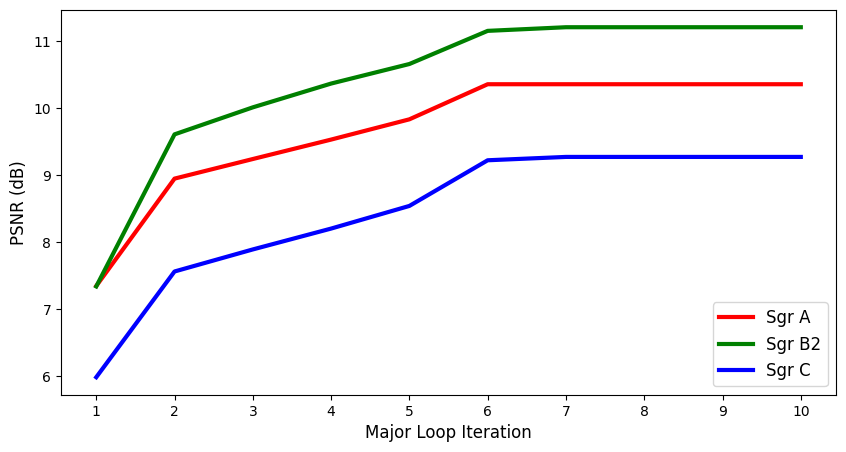

In [45]:
matplotlib.rcParams['figure.figsize'] = [10, 5]

for i, dataset in enumerate(datasets):
    curr_data = singlestep_fulldata[i]
    
    plt.plot(range(1, 11), curr_data, c=colours[i], label=dataset, lw=3)

plt.legend(loc="lower right", fontsize=12)
plt.xticks(range(1, 11))
    
plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("PSNR (dB)", fontsize=12)
plt.savefig("../figures/full_majcycle_conv.png", bbox_inches='tight')

In [47]:
dataset_names = ["Sgr A", "Sgr B", "Sgr C"]
actual_names = ["SGRA", "SGRB", "SGRC"]

mstep_fulldata = []

noiseless = False
weight = "uniform"
lambdam = 2

for i, dataset in enumerate(actual_names):
    gt = util.fromfits("../data/" + dataset + "_full_gt.fits")
    
    snr_full_fullres = []
    snr_low_fullres = []

    path =  "../results/cut_results/" + dataset + "/20/5hw/bphigh/lambda_m" + str(lambdam) + "/"

    low_gt_filter = split.bandpass(gt, 0, cut + hw)
    low_gt = signal.fftconvolve(gt, low_gt_filter, mode='same')

    curr_deconv_low = None
    curr_deconv_high = None
    for maj_iter in range(0, 5):
        high_filename = path + "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
        low_filename = "../results/cut_results/" + dataset + "/35/5hw/low/" + \
            "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
        deconv_low = util.fromfits(low_filename)
        deconv_high = util.fromfits(high_filename)

        if curr_deconv_low is None:
            curr_deconv_low = deconv_low
        else:
            curr_deconv_low += deconv_low

        if curr_deconv_high is None:
            curr_deconv_high = deconv_high
        else:
            curr_deconv_high += deconv_high

        snr_full_fullres.append(evaluation.compute_snr(gt, curr_deconv_high))
        snr_low_fullres.append(evaluation.compute_snr(gt, curr_deconv_low))

    mstep_fulldata.append(snr_low_fullres + snr_full_fullres)

In [48]:
colours = ['r', 'g', 'b']
datasets = ["Sgr A", "Sgr B2", "Sgr C"]
actual_datasets = ["SGRA", "SGRB", "SGRC"]
gts = [util.fromfits("../data/SGRA_full_gt.fits"), util.fromfits("../data/SGRB_full_gt.fits"), \
       util.fromfits("../data/SGRC_full_gt.fits")]

msclean_fulldata = []

for i, dataset in enumerate(actual_datasets):
    gt = gts[i]
    curr_data = []
    curr_deconv = None
    for maj_iter in range(0, 10):
        filename = "../results/msclean/" + dataset + "/mscleanmodel_" + str(maj_iter) + ".fits"
        deconv = util.fromfits(filename)

        if curr_deconv is None:
            curr_deconv = deconv
        else:
            curr_deconv += deconv
            
        restored = convolve_fft(curr_deconv, gk, normalize_kernel=False, allow_huge=True, boundary="wrap")

        psnr = evaluation.compute_snr(gt, restored)
        
        #helpers.plotNImages([restored], [str(psnr)], cmap=cmap)
        
        curr_data.append(psnr)

    msclean_fulldata.append(curr_data)

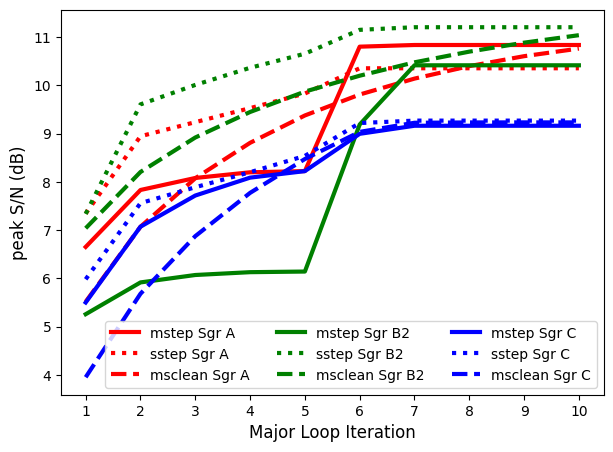

In [49]:
matplotlib.rcParams['figure.figsize'] = [7, 5]

for i, dataset in enumerate(datasets):
    curr_data = mstep_fulldata[i]
    
    plt.plot(range(1, 11), curr_data, linestyle='-',c=colours[i], label="mstep " + dataset, lw=3)
    
    curr_sstepdata = singlestep_fulldata[i]
    
    plt.plot(range(1, 11), curr_sstepdata, linestyle=':', c=colours[i], label="sstep " + dataset, lw=3)
    
    curr_mscleandata = msclean_fulldata[i]
    
    plt.plot(range(1, 11), curr_mscleandata, linestyle='--', c=colours[i], label="msclean " + dataset, lw=3)

plt.legend(loc="lower right", fontsize=10, ncol=3)
plt.xticks(range(1, 11))
    
plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("peak S/N (dB)", fontsize=12)
plt.savefig("../figures/full_majcycle_conv.png", bbox_inches='tight')

-1.221280364518529


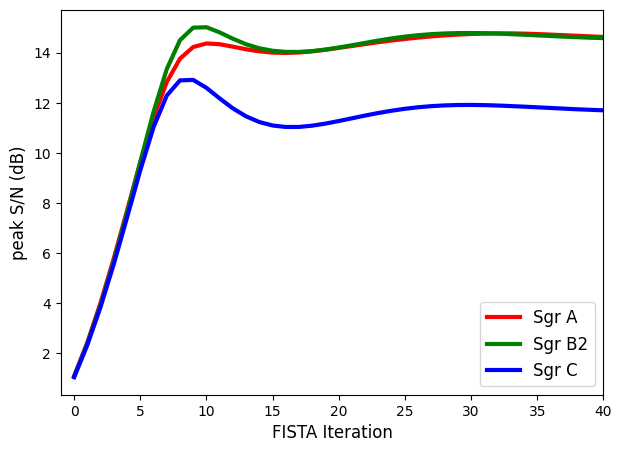

In [51]:
matplotlib.rcParams['figure.figsize'] = [7, 5]

actual_names = ["SGRA", "SGRB", "SGRC"]

colours = ['r', 'g', 'b']
labels = ["Sgr A", "Sgr B2", "Sgr C"]

test = util.fromfits("tmp_output.fits")
gt = util.fromfits("../data/SGRC_full_gt.fits")
print(evaluation.compute_snr(gt, test))

for i, dataset in enumerate(actual_names):
    gt = util.fromfits("../data/" + dataset + "_full_gt.fits")
    csv_name = "../results/cut_results/fista_convergence/" + dataset + "_full.csv"
    data = util.read_csv(csv_name)
    data = data[1:]
    data = [float(x) for x in data]
    data = [20 * numpy.log10(numpy.linalg.norm(gt) / numpy.sqrt(float(x))) for x in data]
    plt.plot(range(0, len(data)), data, c=colours[i], label=labels[i], lw=3)

plt.xlim([-1, 40])

plt.legend(loc="lower right", fontsize=12)
#plt.yscale('log')
#plt.xscale('log')
plt.xlabel("FISTA Iteration", fontsize=12)
plt.ylabel("peak S/N (dB)", fontsize=12)
plt.savefig("../figures/full_fista_conv.png", bbox_inches='tight')
        

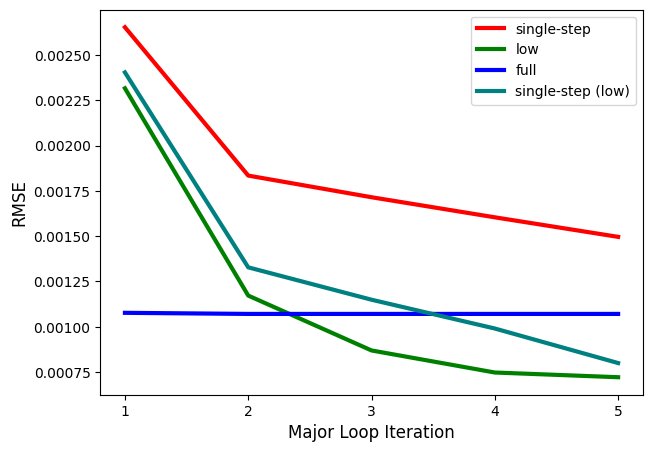

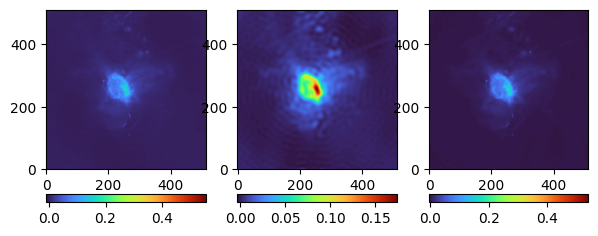

In [52]:
from scipy import signal

colours = ['r', 'g', 'b']
fullgt = util.fromfits("../data/SGRA_full_gt.fits")
lowgt = util.fromfits("../data/SGRA_low25_gt.fits")
delta = 5
cut = 20

low_dat = []
high_dat = []
single_dat = []
single_largescale_dat = []

curr_deconv_single = None
curr_deconv_low = None
curr_deconv_high = None

bpfilter = split.bandpass(lowgt, 0, cut + delta)
lowgt_bp = signal.fftconvolve(lowgt, bpfilter, mode='same')

for maj_iter in range(0, 5):
    single_filename = "../results/cut_results/full_recons/SGRA/deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
    low_filename = "../results/cut_results/SGRA/" + str(cut) + "/" + str(delta) + "hw/low/" + \
                        "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
    high_filename = "../results/cut_results/SGRA/" + str(cut) + "/" + str(hw) + "hw/high/" + \
                    "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
    
    deconv_single = util.fromfits(single_filename)
    deconv_low = util.fromfits(low_filename)
    deconv_high = util.fromfits(high_filename)

    if curr_deconv_single is None:
        curr_deconv_single = deconv_single
    else:
        curr_deconv_single += deconv_single
        
    if curr_deconv_low is None:
        curr_deconv_low = deconv_low
    else:
        curr_deconv_low += deconv_low
        
    if curr_deconv_high is None:
        curr_deconv_high = deconv_high
    else:
        curr_deconv_high += deconv_high

    single_bp_deconv = signal.fftconvolve(curr_deconv_single, bpfilter, mode='same')
        
    rmse_single = evaluation.compute_rmse(fullgt, curr_deconv_single)
    rmse_low = evaluation.compute_rmse(lowgt, curr_deconv_low)
    rmse_high = evaluation.compute_rmse(fullgt, curr_deconv_high)
    rmse_single_largescale = evaluation.compute_rmse(single_bp_deconv, lowgt_bp)
    
    single_dat.append(rmse_single)
    low_dat.append(rmse_low)
    high_dat.append(rmse_high)
    single_largescale_dat.append(rmse_single_largescale)

plt.plot(range(1, 6), single_dat, c='r', label="single-step", lw=3)
plt.plot(range(1, 6), low_dat, c='g', label="low", lw=3)
plt.plot(range(1, 6), high_dat, c='b', label="full", lw=3)
plt.plot(range(1, 6), single_largescale_dat, c='teal', label="single-step (low)", lw=3)


plt.legend(loc="upper right",  fontsize=10)
plt.xticks([1,2,3,4,5])

plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("RMSE", fontsize=12)
plt.savefig("../figures/singlevsmulti_majcyc.png", bbox_inches='tight')

util.plotNImages([curr_deconv_single, curr_deconv_low, curr_deconv_high], ["", "", ""], cmap=cmap)

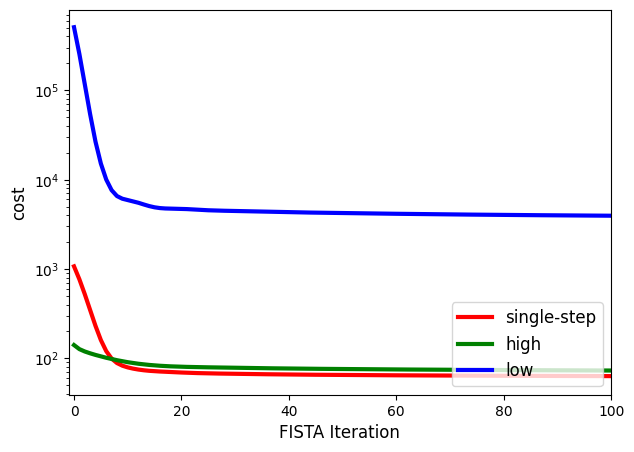

In [54]:
single_costs = "../results/cut_results/fista_convergence/SGRA_cost_full.csv"
high_costs = "../results/cut_results/fista_convergence/SGRA_cost_high15.csv"
low_costs = "../results/cut_results/fista_convergence/SGRA_cost_low25.csv"

def read_costs(filename):
    data = util.read_csv(filename)
    data = data[1:]
    data = [float(x) for x in data]
    
    return data

sc_dat = read_costs(single_costs)
hc_dat = read_costs(high_costs)
lc_dat = read_costs(low_costs)

plt.plot(range(0, len(sc_dat)), sc_dat, c="r", label="single-step", lw=3)
plt.plot(range(0, len(hc_dat)), hc_dat, c="g", label="high", lw=3)
plt.plot(range(0, len(lc_dat)), lc_dat, c="b", label="low", lw=3)

plt.xlim([-1, 100])

plt.legend(loc="lower right", fontsize=12)
plt.yscale('log')

plt.xlabel("FISTA Iteration", fontsize=12)
plt.ylabel(r"cost", fontsize=12)
plt.savefig("../figures/singlevsmulti_fista_conv.png", bbox_inches='tight')
        

## Aggregate PSNR across all bands for noiseless datasets

In [55]:
gts_multistep = [util.fromfits("../data/SGRA_full_gt.fits"), util.fromfits("../data/SGRB_full_gt.fits"), \
       util.fromfits("../data/SGRC_full_gt.fits")]

gts_low = [[[util.fromfits("../data/SGRA_low25_gt.fits"), util.fromfits("../data/SGRA_low23_gt.fits"), util.fromfits("../data/SGRA_low21_gt.fits")], \
            [util.fromfits("../data/SGRA_low40_gt.fits"), util.fromfits("../data/SGRA_low38_gt.fits"), util.fromfits("../data/SGRA_low36_gt.fits")], \
            [util.fromfits("../data/SGRA_low60_gt.fits"), util.fromfits("../data/SGRA_low58_gt.fits"), util.fromfits("../data/SGRA_low56_gt.fits")]], \
            [[util.fromfits("../data/SGRB_low25_gt.fits"), util.fromfits("../data/SGRB_low23_gt.fits"), util.fromfits("../data/SGRB_low21_gt.fits")], \
            [util.fromfits("../data/SGRB_low40_gt.fits"), util.fromfits("../data/SGRB_low38_gt.fits"), util.fromfits("../data/SGRB_low36_gt.fits")], \
            [util.fromfits("../data/SGRB_low60_gt.fits"), util.fromfits("../data/SGRB_low58_gt.fits"), util.fromfits("../data/SGRB_low56_gt.fits")]], \
            [[util.fromfits("../data/SGRC_low25_gt.fits"), util.fromfits("../data/SGRC_low23_gt.fits"), util.fromfits("../data/SGRC_low21_gt.fits")], \
            [util.fromfits("../data/SGRC_low40_gt.fits"), util.fromfits("../data/SGRC_low38_gt.fits"), util.fromfits("../data/SGRC_low36_gt.fits")], \
            [util.fromfits("../data/SGRC_low60_gt.fits"), util.fromfits("../data/SGRC_low58_gt.fits"), util.fromfits("../data/SGRC_low56_gt.fits")]]]

cuts = [20, 35, 55]
hws = [5]
dataset_names = ["Sgr A", "Sgr B2", "Sgr C"]
actual_names = ["SGRA", "SGRB", "SGRC"]

data_low = []
data_high = []

weight = "uniform"
lambdam = 2

for i, dataset in enumerate(actual_names):
    high_gt = gts_multistep[i]
    for j, cut in enumerate(cuts):
        for k, hw in enumerate(hws):
            curr_data_low = [dataset + " " + str(cut) + " " + str(hw)]
            curr_data_high = [dataset + " " + str(cut) + " " + str(hw)]
            
            path = "../results/noiseless_cut_results/" + weight + "/" + dataset + "/" + str(cut) + "/" + str(hw) + \
                "hw/high/lambda_m" + str(lambdam) + "/"
            lowpath = "../results/noiseless_cut_results/" + weight + "/" + dataset + "/" + str(cut) + "/" + str(hw) + \
                "hw/low/lambda_m" + str(lambdam) + "/"
            
            low_gt = gts_low[i][j][k]
            
            curr_deconv_low = None
            curr_deconv_high = None
            
            bpfilter = split.bandpass(low_gt, 0, hw + cut)
            
            for maj_iter in range(0, 5):
                high_filename = path + "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
                low_filename = lowpath + "deconv_iteration_" + str(maj_iter) + "_channel_0.fits"
                deconv_low = signal.fftconvolve(util.fromfits(low_filename), bpfilter, mode='same')
                deconv_high = util.fromfits(high_filename)
                
                if curr_deconv_low is None:
                    curr_deconv_low = deconv_low
                else:
                    curr_deconv_low += deconv_low
                
                if curr_deconv_high is None:
                    curr_deconv_high = deconv_high
                else:
                    curr_deconv_high += deconv_high
                
                psnr_low = evaluation.compute_snr(low_gt, curr_deconv_low)
                psnr_high = evaluation.compute_snr(high_gt, curr_deconv_high)
                
                curr_data_low.append(psnr_low)
                curr_data_high.append(psnr_high)
                
                #if maj_iter == 4:
                #    helpers.plotNImages([curr_deconv_low, curr_deconv_high, high_gt], ["", "", ""], cmap=cmap, same_scale=True)
            
            data_low.append(curr_data_low)
            data_high.append(curr_data_high)

In [56]:
pd.DataFrame(data_low, columns=["Dataset", "1", "2", "3", "4", "5"])

,Dataset,1,2,3,4,5
0,SGRA 20 5,7.820512,10.160369,10.985099,11.428771,11.652383
1,SGRA 35 5,7.511644,9.639896,10.328061,10.710412,10.857329
2,SGRA 55 5,7.004816,8.977478,9.334881,9.362200,9.362200
3,SGRB 20 5,6.477572,7.552633,7.778948,7.874847,7.942610
4,SGRB 35 5,6.035285,6.767589,6.920594,6.983443,7.010116
5,SGRB 55 5,5.419522,6.195014,6.269390,6.272553,6.272553
6,SGRC 20 5,6.308915,8.477726,9.573331,10.295201,10.811074
7,SGRC 35 5,6.052215,8.148913,9.206907,9.842619,9.997558
8,SGRC 55 5,5.589694,7.469880,8.033945,8.138102,8.138102


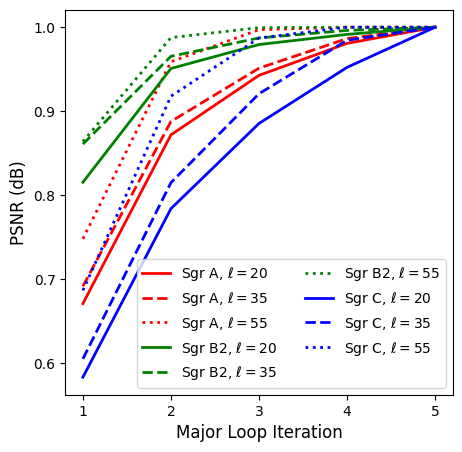

In [58]:
matplotlib.rcParams['figure.figsize'] = [5, 5]

colours = ['r', 'r', 'r', 'g', 'g', 'g', 'b', 'b', 'b']
styles = ['-', '--', ':', '-', '--', ':', '-', '--', ':']
labels = ["Sgr A, $\ell=20$", "Sgr A, $\ell=35$", "Sgr A, $\ell=55$", \
         "Sgr B2, $\ell=20$", "Sgr B2, $\ell=35$", "Sgr B2, $\ell=55$", \
         "Sgr C, $\ell=20$", "Sgr C, $\ell=35$", "Sgr C, $\ell=55$"]

for i, data in enumerate(data_low):
    cleaned_data = data[1:]
    norm_factor = numpy.max(cleaned_data)
    cleaned_data = [x / norm_factor for x in cleaned_data]

    plt.plot(range(1, 6), cleaned_data, c=colours[i], linestyle=styles[i], label=labels[i], lw=2)

plt.xticks([1,2,3,4,5])
    
plt.legend(loc="lower right", fontsize=10, ncol=2)
    
plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("PSNR (dB)", fontsize=12)
plt.savefig("../figures/low_majcycle_conv_noiseless.png", bbox_inches='tight')

In [59]:
pd.DataFrame(data_high, columns=["Dataset", "1", "2", "3", "4", "5"])

,Dataset,1,2,3,4,5
0,SGRA 20 5,11.517044,13.335194,13.585010,13.659776,13.664513
1,SGRA 35 5,11.163322,12.149670,12.241662,12.248506,12.248506
2,SGRA 55 5,9.654980,10.505798,10.521374,10.521955,10.521955
3,SGRB 20 5,7.658388,10.262329,10.873175,11.134430,11.180567
4,SGRB 35 5,8.567996,10.110889,10.436212,10.514862,10.519695
5,SGRB 55 5,8.924440,9.413326,9.479951,9.483234,9.483234
6,SGRC 20 5,8.950258,10.111686,10.414215,10.745752,11.127358
7,SGRC 35 5,9.446346,10.084401,10.265991,10.306388,10.309930
8,SGRC 55 5,8.283213,8.580997,8.614881,8.616330,8.616330


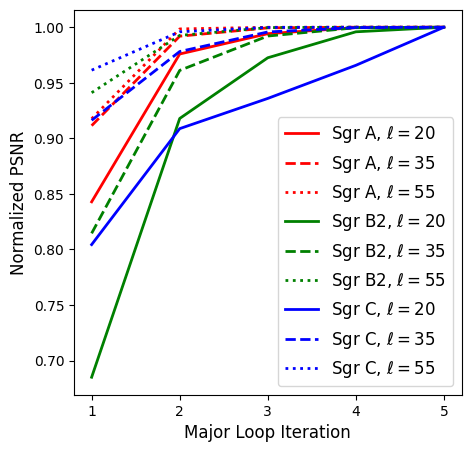

In [60]:
colours = ['r', 'r', 'r', 'g', 'g', 'g', 'b', 'b', 'b']
styles = ['-', '--', ':', '-', '--', ':', '-', '--', ':']
labels = ["Sgr A, $\ell=20$", "Sgr A, $\ell=35$", "Sgr A, $\ell=55$", \
         "Sgr B2, $\ell=20$", "Sgr B2, $\ell=35$", "Sgr B2, $\ell=55$", \
         "Sgr C, $\ell=20$", "Sgr C, $\ell=35$", "Sgr C, $\ell=55$"]

for i, data in enumerate(data_high):
    cleaned_data = data[1:]
    norm_factor = numpy.max(cleaned_data)
    cleaned_data = [x / norm_factor for x in cleaned_data]
    plt.plot(range(1, 6), cleaned_data, c=colours[i], linestyle=styles[i], label=labels[i], lw=2)


    
plt.legend(loc="lower right", fontsize=12)
plt.xticks([1,2,3,4,5])

plt.xlabel("Major Loop Iteration", fontsize=12)
plt.ylabel("Normalized PSNR", fontsize=12)
plt.savefig("../figures/high_majcycle_conv_noiseless.png", bbox_inches='tight')